# Задание 10. Подготовка датасета URL

**Проект:** SMS Guard · **Автор:** Омаров М.Е., SIS-2304

Набор: **PhiUSIIL Phishing URL Dataset** (UCI, id 967). Загрузка — `python -m ml.data.download_urls`,
подготовка — `python -m ml.data.prepare_urls`. Паспорт набора — `docs/10_url_dataset.md`.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

from ml.data import prepare_urls as pu  # noqa: E402
from ml.url_features import MODEL_FEATURES, extract_url_features  # noqa: E402

FIG_DIR = PROJECT_ROOT / "docs" / "figures"
raw = pd.read_csv(pu.RAW_PATH, encoding="utf-8-sig")
print("Строк и столбцов:", raw.shape)
print("Пропусков всего:", int(raw.isna().sum().sum()))
raw[["URL", "Domain", "TLD", "IsHTTPS", "label"]].head()

Строк и столбцов: (235795, 56)
Пропусков всего: 0


,URL,Domain,TLD,IsHTTPS,label
0,https://www.southbankmosaics.com,www.southbankmosaics.com,com,1,1
1,https://www.uni-mainz.de,www.uni-mainz.de,de,1,1
2,https://www.voicefmradio.co.uk,www.voicefmradio.co.uk,uk,1,1
3,https://www.sfnmjournal.com,www.sfnmjournal.com,com,1,1
4,https://www.rewildingargentina.org,www.rewildingargentina.org,org,1,1


## 1. Структура и метки

В наборе 56 столбцов: `FILENAME` (не используется), `URL`, 54 признака и `label`. Большинство признаков
(`LineOfCode`, `HasTitle`, `NoOfImage`, `HasPasswordField` …) получены **при загрузке страницы**. Система страницы
не загружает (раздел 2.3 ТЗ), поэтому из набора берутся только столбцы `URL` и `label`, а все признаки
вычисляются заново функцией `ml.url_features`, которая работает в приложении.

**Метки.** В исходнике `1` — легитимный, `0` — фишинг. В проекте наоборот: `1` — фишинг (опасный), `0` — безопасный.

In [2]:
raw["y"] = 1 - raw["label"]
balance = raw["y"].value_counts().rename({0: "безопасный (0)", 1: "фишинг (1)"}).to_frame("URL")
balance["доля, %"] = (balance["URL"] / len(raw) * 100).round(2)
balance

,URL,"доля, %"
y,,
безопасный (0),134850,57.19
фишинг (1),100945,42.81


## 2. Артефакт разметки

Проверим, как выглядят URL разных классов.

In [3]:
def pattern(u: str) -> str:
    scheme = "https://" if u.startswith("https://") else "http://" if u.startswith("http://") else "без схемы"
    www = "www." if u.split("://", 1)[-1].startswith("www.") else ""
    return scheme + www


raw["шаблон начала"] = raw["URL"].map(pattern)
raw["есть путь"] = raw["URL"].str.split("://", n=1).str[-1].str.contains("/", regex=False)
art = pd.crosstab(raw["шаблон начала"], raw["y"].map({0: "безопасный", 1: "фишинг"}), margins=True, margins_name="всего")
art

y,безопасный,фишинг,всего
шаблон начала,,,
http://,0,12452,12452
http://www.,0,39297,39297
https://,0,46747,46747
https://www.,134850,2449,137299
всего,134850,100945,235795


In [4]:
print("Доля URL с путём после домена:")
print(raw.groupby("y")["есть путь"].mean().rename({0: "безопасный", 1: "фишинг"}).round(4))
rule = (~raw["URL"].str.startswith("https://www.") | raw["есть путь"]).astype(int)
print(f"\nПравило «не https://www. или есть путь → фишинг» без всякого ML: "
      f"accuracy {(rule == raw['y']).mean():.4f}, recall {rule[raw['y'] == 1].mean():.4f}, "
      f"ложных тревог {rule[raw['y'] == 0].sum()}")

Доля URL с путём после домена:
y
безопасный    0.0000
фишинг        0.5986
Name: есть путь, dtype: float64

Правило «не https://www. или есть путь → фишинг» без всякого ML: accuracy 0.9973, recall 0.9938, ложных тревог 0


**Вывод.** Все 134 850 безопасных URL имеют вид `https://www.домен` и ведут только на главную страницу (пути нет ни у одного).
У фишинговых — любые схемы, пути и `/` на конце. Тривиальное правило по началу строки уже даёт accuracy ≈ 0,99 и не
ошибается на безопасных. Модель, обученная на исходных URL, выучит именно его, а на реальной ссылке вида
`https://kaspi.kz/shop` (с путём) или `kaspi.kz` (без схемы) будет ошибаться.

**Решение.** Каждый URL приводится к канонической форме `http://домен[:порт]` (`canonical_url`): схема, `www.`, путь
и параметры отбрасываются. Модель получает 17 признаков домена (`MODEL_FEATURES`); признаки пути, схемы и `@`
(`url_length`, `path_length`, `path_depth`, `n_query_params`, `double_slash_path`, `has_at`, `is_https`) по-прежнему
считаются и показываются пользователю в объяснении, но в модель не входят.

## 3. Очистка

In [5]:
df, steps = pu.clean(raw[["URL", "label"]])
steps_table = pd.DataFrame(steps, columns=["Шаг", "Записей", "Примечание"])
steps_table.index = range(1, len(steps_table) + 1)
steps_table

,Шаг,Записей,Примечание
1,Исходные записи,235795,"PhiUSIIL, столбцы URL и label"
2,Удалены пустые URL,0,
3,Удалены некорректные URL,8,"validate_url: пробелы, нет домена и т. п."
4,Удалены точные дубликаты URL,425,
5,Каноническая форма http://домен,235362,"схема, www., путь и запрос отброшены"
6,Удалены домены с противоречивыми метками,159,58 доменов
7,Удалены дубликаты доменов,16163,в основном фишинговые URL с разными путями на одном домене


In [6]:
print("После очистки:", df["label"].value_counts().rename({0: "безопасный", 1: "фишинг"}).to_dict())
print("Доля фишинга: {:.2%}".format(df["label"].mean()))

После очистки: {'безопасный': 134792, 'фишинг': 84248}
Доля фишинга: 38.46%


## 4. Подвыборка и разбиение по доменам

Стратифицированная подвыборка 100 000 записей с сохранением доли классов, затем `GroupShuffleSplit` 70/15/15 по
регистрируемому домену (`registered_domain`, на основе `tldextract`): все поддомены одного домена попадают в одну выборку.

In [7]:
data = pd.read_csv(pu.DATASET_PATH)
features = pu.load_url_features()
split_table = data.groupby("split").agg(записей=("id", "size"), фишинг=("label", "sum"),
                                        доля_фишинга=("label", "mean"),
                                        доменов=("registered_domain", "nunique")).loc[["train", "val", "test"]]
split_table["доля_фишинга"] = (split_table["доля_фишинга"] * 100).round(2)
domains = {p: set(data.loc[data["split"] == p, "registered_domain"]) for p in ("train", "val", "test")}
print("Общих доменов: train∩val =", len(domains["train"] & domains["val"]), ", train∩test =",
      len(domains["train"] & domains["test"]), ", val∩test =", len(domains["val"] & domains["test"]))
split_table

Общих доменов: train∩val = 0 , train∩test = 0 , val∩test = 0


,записей,фишинг,доля_фишинга,доменов
split,,,,
train,70098,27121,38.69,56870
val,14052,4831,34.38,12186
test,15850,6510,41.07,12187


In [8]:
print("Самые крупные домены и выборки, в которые они попали:")
top = data["registered_domain"].value_counts().head(8).index
data[data["registered_domain"].isin(top)].groupby(["registered_domain", "split"]).size().unstack(fill_value=0)

Самые крупные домены и выборки, в которые они попали:


split,test,train,val
registered_domain,,,
dweb.link,0,0,358
firebaseapp.com,2465,0,0
repl.co,0,1562,0
square.site,0,469,0
web.app,0,2532,0
weeblysite.com,0,1325,0
workers.dev,0,0,586
xsph.ru,0,391,0


Доля фишинга в выборках различается (34–41%): крупные хостинги фишинговых страниц попадают в выборку целиком.
Например, все 2465 доменов на `firebaseapp.com` оказались в test — модель их при обучении не увидит. Это делает тест
строже: он проверяет, как модель распознаёт фишинг на незнакомом хостинге.

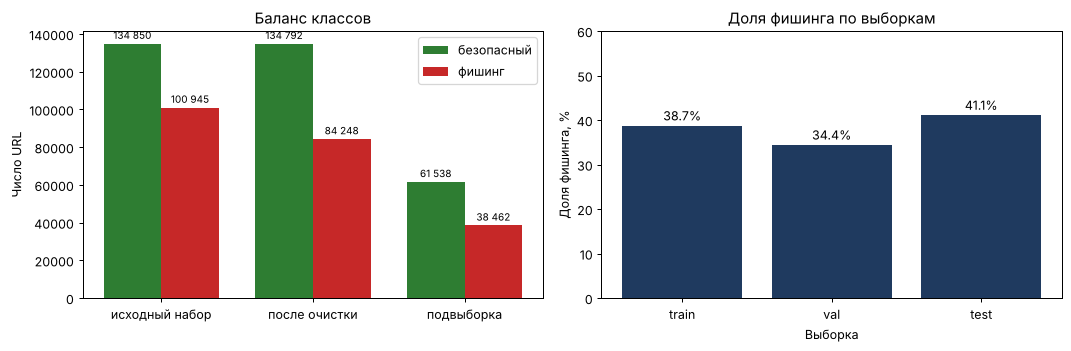

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = [raw["y"].value_counts().sort_index(), df["label"].value_counts().sort_index(),
          data["label"].value_counts().sort_index()]
labels = ["исходный набор", "после очистки", "подвыборка"]
x = np.arange(3)
for i, (cls, color, name) in enumerate([(0, "#2e7d32", "безопасный"), (1, "#c62828", "фишинг")]):
    vals = [c[cls] for c in counts]
    b = axes[0].bar(x + (i - 0.5) * 0.38, vals, 0.38, color=color, label=name)
    axes[0].bar_label(b, labels=[f"{v:,}".replace(",", " ") for v in vals], fontsize=8, padding=2)
axes[0].set_xticks(x, labels)
axes[0].set_ylabel("Число URL")
axes[0].set_title("Баланс классов")
axes[0].legend()
share = split_table["доля_фишинга"]
b = axes[1].bar(share.index, share.values, color="#1f3a5f")
axes[1].bar_label(b, labels=[f"{v:.1f}%" for v in share.values], padding=2)
axes[1].set_ylim(0, 60)
axes[1].set_ylabel("Доля фишинга, %")
axes[1].set_xlabel("Выборка")
axes[1].set_title("Доля фишинга по выборкам")
fig.tight_layout()
fig.savefig(FIG_DIR / "10_url_balance.png", dpi=150)

## 5. Признаки по классам (обучающая выборка)

In [10]:
train_f = features[features["split"] == "train"]
means = train_f.groupby("label")[MODEL_FEATURES].mean().T.round(3)
means.columns = ["безопасный", "фишинг"]
means["отношение фишинг / безопасный"] = (means["фишинг"] / means["безопасный"].replace(0, np.nan)).round(2)
means

,безопасный,фишинг,отношение фишинг / безопасный
host_length,15.232,22.378,1.47
n_dots,1.161,1.754,1.51
n_subdomains,0.030,0.718,23.93
n_hyphens_host,0.083,0.583,7.02
n_digits,0.050,2.084,41.68
digit_ratio_host,0.004,0.077,19.25
n_special,0.083,0.583,7.02
has_ip,0.000,0.002,NaN
nonstandard_port,0.000,0.000,NaN
is_shortener,0.000,0.000,NaN


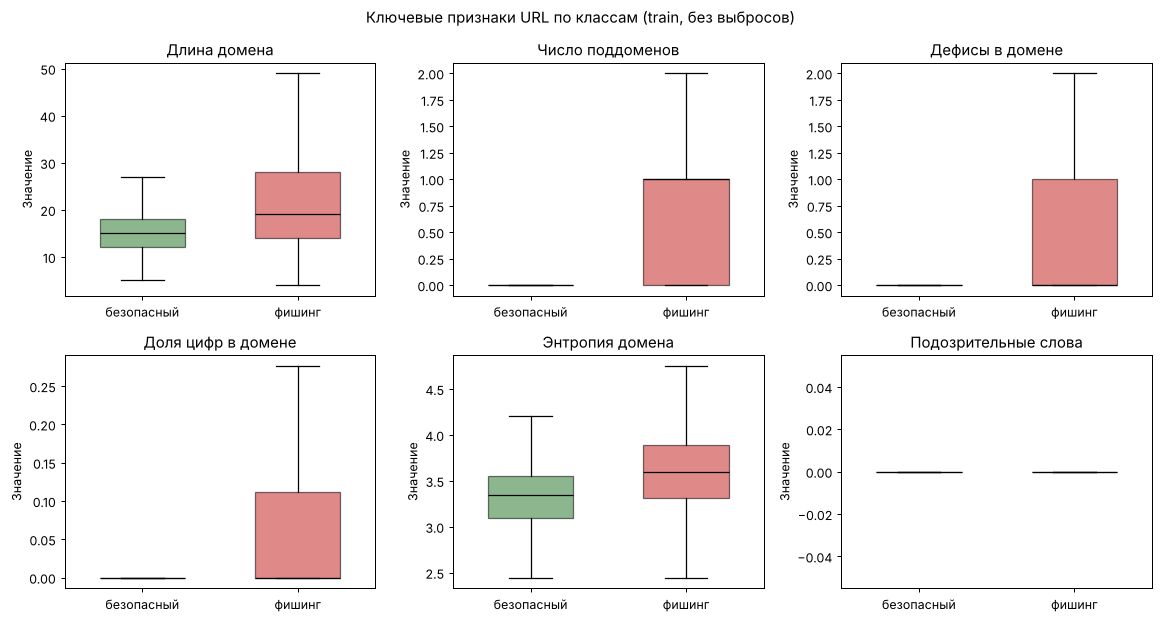

In [11]:
key = ["host_length", "n_subdomains", "n_hyphens_host", "digit_ratio_host", "host_entropy", "n_suspicious_words"]
titles = {"host_length": "Длина домена", "n_subdomains": "Число поддоменов", "n_hyphens_host": "Дефисы в домене",
          "digit_ratio_host": "Доля цифр в домене", "host_entropy": "Энтропия домена",
          "n_suspicious_words": "Подозрительные слова"}
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), key):
    data_cls = [train_f.loc[train_f["label"] == c, col] for c in (0, 1)]
    bp = ax.boxplot(data_cls, patch_artist=True, widths=0.55, showfliers=False, medianprops={"color": "black"})
    for patch, color in zip(bp["boxes"], ("#2e7d32", "#c62828")):
        patch.set_facecolor(color)
        patch.set_alpha(0.55)
    ax.set_xticks([1, 2], ["безопасный", "фишинг"])
    ax.set_title(titles[col])
    ax.set_ylabel("Значение")
fig.suptitle("Ключевые признаки URL по классам (train, без выбросов)")
fig.tight_layout()
fig.savefig(FIG_DIR / "10_url_features_boxplot.png", dpi=150)

In [12]:
binary = ["has_ip", "is_shortener", "has_punycode", "mixed_scripts", "brand_similarity", "suspicious_tld",
          "brand_in_url", "nonstandard_port"]
(train_f.groupby("label")[binary].mean().T * 100).round(2).rename(columns={0: "безопасный, %", 1: "фишинг, %"})

label,"безопасный, %","фишинг, %"
has_ip,0.00,0.23
is_shortener,0.00,0.01
has_punycode,0.00,0.18
mixed_scripts,0.00,0.00
brand_similarity,0.27,0.12
suspicious_tld,0.06,9.37
brand_in_url,0.13,1.52
nonstandard_port,0.00,0.03


## 6. Выводы

1. **Набор:** 235 795 URL без пропусков, 134 850 безопасных (57,2%) и 100 945 фишинговых (42,8%) — точно как в описании UCI. Из 56 столбцов используются только `URL` и `label`; остальные признаки требуют загрузки страницы.
2. **Артефакт разметки найден и устранён.** Все безопасные URL имеют вид `https://www.домен` без пути; правило «не `https://www.` или есть путь → фишинг» без всякого ML даёт accuracy 0,997 при нуле ложных тревог. URL приведены к канонической форме `http://домен`, модель получает только 17 признаков домена.
3. **Очистка:** 8 некорректных URL, 425 точных дубликатов, 58 доменов с противоречивыми метками (159 записей), 16 163 дубликата доменов (фишинговые URL с разными путями на одном домене). Осталось 219 040 доменов, из них стратифицированная подвыборка — 100 000 (38,5% фишинга).
4. **Разбиение по регистрируемому домену:** train 70 098, val 14 052, test 15 850; общих доменов между выборками нет. Доля фишинга по выборкам 34–41%: крупные хостинги попадают в одну выборку целиком (весь `firebaseapp.com` — в test), поэтому test проверяет распознавание фишинга на незнакомом хостинге.
5. **Признаки по классам (train):** у фишинговых доменов больше поддоменов (0,72 против 0,03 в среднем), цифр (2,08 против 0,05), дефисов (0,58 против 0,08), они длиннее (22,4 против 15,2 символа); подозрительная зона — у 9,4% фишинговых и 0,06% безопасных, название бренда в чужом домене — 1,5% против 0,1%.
6. **Ограничения.** IP-адреса (0,23%), Punycode (0,18%) и сокращатели ссылок (единицы) в наборе почти не встречаются, поэтому модель их практически не выучит; эти случаи дополнительно учитывают правила модуля риска (задание 13). Безопасные URL в наборе — главные страницы популярных сайтов, поэтому модель может хуже оценивать безопасные адреса малоизвестных сайтов.